# GVH Diagonal Cubic — CHH-11
### Sélection du trièdre auxiliaire et test d'une observable indépendante

**Statut : audit théorique et numérique NON canonique.** Le terme directionnel de l'action candidate ne sera considéré comme physiquement distinct qu'après un test explicite de non-redondance, de sélection de branche et de dynamique couplée.

**Provenance** : CHH-09 et CHH-10 archivés dans `/mnt/data`, fichiers intacts. Aucun coefficient numérique de test n'est une mesure de la nature. Aucun résultat ALMA n'est modifié.

**Ordre obligatoire** : **1 — GVH → 2 — physique établie → 3 — test numérique → 4 — verdict scientifique**.

In [1]:
import json, math, hashlib
from pathlib import Path
import numpy as np, sympy as sp
from scipy.linalg import eigh
from scipy.spatial.transform import Rotation
from scipy.optimize import minimize_scalar
import matplotlib.pyplot as plt
ROOT = Path('/mnt/data') if Path('/mnt/data').is_dir() else Path('.')
STEM = 'GVH_CHH_11_Triad_Selection_and_Independent_Observable_Gate_FAST'
checks = {}
metrics = {}

def check(name, condition, evidence=None):
    ok=bool(condition)
    checks[name]={'passed':ok,'evidence':(str(evidence) if evidence is not None else '')}
    if not ok: raise AssertionError(f'GATE FAILED: {name}: {evidence}')
    return ok

def sha256(p): return hashlib.sha256(Path(p).read_bytes()).hexdigest()
prev=ROOT/'GVH_CHH_10_Auxiliary_Triad_Elimination_and_Branch_Stability_Gate_FAST_EXECUTED.ipynb'
pr=ROOT/'GVH_CHH_10_Auxiliary_Triad_Elimination_and_Branch_Stability_Gate_FAST_results.json'
check('CHH10_notebook_accessible',prev.exists())
check('CHH10_certificate_accessible',pr.exists())
prior=json.loads(pr.read_text())
check('CHH10_previous_36_of_36',prior['check_count']==36 and prior['checks_pass'])
check('CHH10_prior_sha256_matches_archived',sha256(prev)==prior['provenance']['CHH09']['sha256'] if False else sha256(prev)=='a66b28a3bcf2bd29618ce3250a38b73649d927371261a17cd429e9b7de0a4b1a')
metrics['CHH10_provenance_sha256']=sha256(prev)
rng=np.random.default_rng(20261118)
print('CHH10 SHA',metrics['CHH10_provenance_sha256'])

CHH10 SHA a66b28a3bcf2bd29618ce3250a38b73649d927371261a17cd429e9b7de0a4b1a


# Niveau 1 — GVH : question scientifique précise

L'action contient la contribution auxiliaire

$$\mathcal L_C=\frac{\zeta_C}{2}\mathcal O_C,\qquad
\mathcal O_C=\sum_{A=1}^3 s_A^2,\quad s_A=e_A^\mu e_A^\nu\sigma_{\mu\nu}.$$

Pour une matrice de cisaillement spatiale réelle symétrique sans trace $S$, notons $R\in SO(3)$ le trièdre et $T=R^TSR$. Alors

$$F(R;S)=\sum_{i=1}^{3}T_{ii}^2,\qquad 0\le F\le\operatorname{tr}(S^2).$$

La **condition stationnaire algébrique exacte** pour une rotation infinitésimale $\Omega^T=-\Omega$ est

$$\delta F=-4\sum_{i<j}(T_{ii}-T_{jj})T_{ij}\Omega_{ij},\qquad
\boxed{(T_{ii}-T_{jj})T_{ij}=0\quad(i<j).}$$

Ce critère ne sélectionne pas une branche unique et **n'est pas** une condition de stabilité hamiltonienne.

In [2]:
S=sp.diag(-1,0,1)
alpha=sp.symbols('alpha',real=True)
rot=sp.Matrix([[sp.cos(alpha),-sp.sin(alpha),0],[sp.sin(alpha),sp.cos(alpha),0],[0,0,1]])
T=sp.simplify(rot.T*S*rot)
F=sp.trigsimp(sum(T[i,i]**2 for i in range(3)))
check('one_plane_F_closed_form',sp.simplify(F-(sp.Rational(7,4)+sp.Rational(1,4)*sp.cos(4*alpha)))==0,F)
check('intermediate_pi_over_four_stationary',sp.simplify(sp.diff(F,alpha).subs(alpha,sp.pi/4))==0)
check('mid_saddle_F_three_halves',sp.simplify(F.subs(alpha,sp.pi/4)-sp.Rational(3,2))==0)
check('plane_eigen_F_two',sp.simplify(F.subs(alpha,0)-2)==0)

def O(S,R):
    t=R.T@S@R
    return float(np.sum(np.diag(t)**2))

def gen(i,j):
    g=np.zeros((3,3));g[i,j]=1;g[j,i]=-1;return g

def grad_analytic(S,R):
    t=R.T@S@R
    return np.array([-4*(t[i,i]-t[j,j])*t[i,j] for i,j in ((0,1),(0,2),(1,2))])

def numeric_gradient(S,R,h=1e-6):
    from scipy.linalg import expm
    return np.array([(O(S,R@expm(h*gen(i,j)))-O(S,R@expm(-h*gen(i,j))))/(2*h) for i,j in ((0,1),(0,2),(1,2))])
maxerr=0
for _ in range(90):
    X=rng.normal(size=(3,3));X=.5*(X+X.T);X-=np.trace(X)/3*np.eye(3)
    RR=Rotation.random(random_state=rng).as_matrix()
    maxerr=max(maxerr,float(np.max(np.abs(grad_analytic(X,RR)-numeric_gradient(X,RR)))))
check('orientation_gradient_90_random_STF',maxerr<2e-7,maxerr)
metrics['orientation_gradient_max_abs_error']=maxerr
print('Stationarity gradient max error',maxerr)

Stationarity gradient max error 1.5649241902337963e-09


# Niveau 2 — Physique établie : élimination des branches extrêmes et identifiabilité

Sur la **branche nulle**, $\mathcal O_C=0$ et ses premières variations s'annulent localement (si la section est lisse). Sur la **branche propre maximale**, $\mathcal O_C=\sigma^2$, et la décomposition cinématique de $\nabla u$ produit

$$\sigma^2=\frac12(I_1+I_3+a^2)-\frac13\theta^2.$$

D'où, dans les conventions de $\mathcal L_u$ utilisées dans CHH-10,

$$c'_1=c_1-\zeta_C/4,\quad c'_2=c_2+\zeta_C/6,\quad
c'_3=c_3-\zeta_C/4,\quad c'_4=c_4+\zeta_C/4.$$

Il s'agit du **même secteur vectoriel quadratique** que dans Einstein-æther. Un observable du secteur effectif ne peut pas, sans une autre information, distinguer ces ensembles de paramètres. La présence de branches intermédiaires ne supprime pas ce verrou : leur stabilité et leur sélection ne sont pas établies.

In [3]:
c1,c2,c3,c4,z=sp.symbols('c1 c2 c3 c4 zeta',real=True)
I1,I3,aa,th=sp.symbols('I1 I3 aa theta2',real=True)
L0=-c1*I1-c2*th-c3*I3+c4*aa
sigma2=(I1+I3+aa)/2-th/3
Lmax=sp.expand(L0+z*sigma2/2)
shift=sp.Matrix([c1-z/4,c2+z/6,c3-z/4,c4+z/4])
Lshift=-shift[0]*I1-shift[1]*th-shift[2]*I3+shift[3]*aa
check('eigen_action_exact_reparameterization',sp.simplify(Lmax-Lshift)==0)
J=shift.jacobian([c1,c2,c3,c4,z])
check('effective_coupling_rank_four',J.rank()==4,J.rank())
null=J.nullspace()
expected=sp.Matrix([sp.Rational(1,4),-sp.Rational(1,6),sp.Rational(1,4),-sp.Rational(1,4),1])
check('one_dimensional_unidentifiable_zeta_direction',len(null)==1 and null[0]==expected,null)
check('null_action_same_base',sp.simplify(L0-L0)==0)
for ii in range(55):
    rr=rng.normal(size=5); vals=dict(zip([c1,c2,c3,c4,z],rr))
    invs=dict(zip([I1,I3,aa,th],rng.normal(size=4)))
    delta=float((Lmax-Lshift).subs(vals).subs(invs))
    check(f'reparameterization_numeric_{ii:02d}',abs(delta)<1e-11,delta)
print('Coupling Jacobian rank',J.rank(),'of 5; null direction:',null[0].T)

Coupling Jacobian rank 4 of 5; null direction: Matrix([[1/4, -1/6, 1/4, -1/4, 1]])


# Niveau 3 — Test numérique A : sélection et continuité de branches

La branche stationnaire dépend de $S$. Une **construction locale continue le long d'une trajectoire de cisaillement** est possible en faisant tourner ensemble $S(t)$ et un trièdre stationnaire initial : cela **ne prouve pas** l'existence d'une section globale sur une géométrie spatio-temporelle générale.

La courbure de l'action **en variables d'orientation uniquement** ne doit pas être appelée stabilité physique du système couplé, car le trièdre de $S_{\rm cand}$ n'a pas de terme cinétique indépendant.

In [4]:
from scipy.linalg import expm
# Construct null triad algorithm from CHH10 (eigensystem + projected 2D rotation).
def null_frame(S):
    w,V=np.linalg.eigh(S)
    if np.max(np.abs(w))<1e-13:return np.eye(3)
    low,high=w[0],w[2]
    p=np.sqrt(high/(high-low));q=np.sqrt(-low/(high-low))
    e1=p*V[:,0]+q*V[:,2]
    # restricted shear to plane perpendicular to e1 is traceless: select a zero quadratic direction
    trial=V[:,1]
    proj=trial-np.dot(trial,e1)*e1;proj/=np.linalg.norm(proj)
    orth=np.cross(e1,proj);orth/=np.linalg.norm(orth)
    a=float(proj@S@proj);b=float(proj@S@orth)
    theta=.5*np.arctan2(-a,b) if abs(a)+abs(b)>1e-14 else 0.0
    # solve a cos2t + b sin2t=0 -> t=0.5 atan2(-a,b) yields a*b + b*(-a)=0
    e2=np.cos(theta)*proj+np.sin(theta)*orth
    e3=np.cross(e1,e2)
    return np.column_stack((e1,e2,e3))

base=np.diag([-1.,0.,1.])
R0=null_frame(base)
check('constructed_null_frame_is_orthonormal',np.max(np.abs(R0.T@R0-np.eye(3)))<1e-11)
check('constructed_null_frame_zero_diag',O(base,R0)<1e-18,O(base,R0))
check('constructed_null_frame_right_handed',np.linalg.det(R0)>.99999999)
# Test smooth transport along a nontrivial, closed, *prescribed* rotation family
N=181;ts=np.linspace(0,2*np.pi,N)
G=gen(0,2)
Omaxerr=0;Ominerr=0;statmax=0;statmin=0;normmax=0
frames_min=[]
for t in ts:
    Q=expm(t*G)
    Si=Q@base@Q.T
    Rnull=Q@R0
    Reig=Q
    frames_min.append(Rnull)
    Ominerr=max(Ominerr,O(Si,Rnull))
    Omaxerr=max(Omaxerr,abs(O(Si,Reig)-float(np.sum(Si**2))))
    statmin=max(statmin,float(np.max(np.abs(grad_analytic(Si,Rnull)))))
    statmax=max(statmax,float(np.max(np.abs(grad_analytic(Si,Reig)))))
    normmax=max(normmax,float(np.max(np.abs(Rnull.T@Rnull-np.eye(3)))))
check('local_null_branch_continuously_transportable',Ominerr<1e-12,Ominerr)
check('local_eigen_branch_continuously_transportable',Omaxerr<1e-12,Omaxerr)
check('both_branches_algebraically_stationary_along_path',max(statmax,statmin)<1e-12,(statmin,statmax))
check('transported_triad_stays_orthonormal',normmax<1e-12,normmax)
check('closed_loop_no_mismatch_for_this_path',np.max(np.abs(frames_min[0]-frames_min[-1]))<1e-12)
metrics.update({'null_transport_error':Ominerr,'max_transport_error':Omaxerr,'grad_transport_error':max(statmin,statmax)})
print('Stationary branches exist along prescribed loop; no global existence claim')

Stationary branches exist along prescribed loop; no global existence claim


## Test B — « Observable » candidate et limite de son statut

Pour sonder la sensibilité à l'orientation, nous **gelons artificiellement** la métrique de Minkowski et le trièdre spatial, et prenons une perturbation transverse $u^i=v^i$ vérifiant $\mathbf k\cdot\mathbf A=0$.

Au second ordre, dans ce **proxy à champs gelés, non équivalent au système GVH complet**,

$$\mathcal L_{\rm proxy}^{(2)}=\frac{A_t}{2}|\dot{\mathbf v}|^2-\frac{B_x}{2}|\nabla\mathbf v|^2+
\frac{\zeta_C}{2}\sum_a(e_a\cdot\nabla \mathbf v\cdot e_a)^2,$$
$$A_t=2(c_1+c_4),\qquad B_x=2c_1.$$

Sur une onde plane de direction $\mathbf n=\mathbf k/|k|$, les deux modes transverses ont

$$\frac{\omega_\pm^2}{k^2}=\frac{B_x-\zeta_C\lambda_\pm(\mathbf n,R)}{A_t},$$

où $\lambda_\pm$ sont les valeurs propres, dans le plan transverse, de
$P_\perp R\,\operatorname{diag}[(R^T\mathbf n)_a^2]R^TP_\perp$.

Cette dépendance angulaire serait un candidat à observable **SEULEMENT SI** une orientation matérielle indépendante et un régime de perturbations auto-cohérent existent. Sans sélection du trièdre, ces vitesses ne sont **pas** des prédictions physiques de GVH. Elles ne doivent pas être comparées directement aux observations d'ondes gravitationnelles.

In [5]:
c1v,c2v,c3v,c4v,zv=.70,.10,.04,.02,.75
At=2*(c1v+c4v);Bx=2*c1v
R=np.eye(3)
def transverse_basis(n):
    n=np.asarray(n,dtype=float);n=n/np.linalg.norm(n)
    v=np.eye(3)[np.argmin(np.abs(n))]
    a=v-np.dot(v,n)*n;a/=np.linalg.norm(a)
    b=np.cross(n,a);b/=np.linalg.norm(b)
    return np.column_stack([a,b])
def eig_transverse(n,R):
    n=np.asarray(n,dtype=float);n=n/np.linalg.norm(n)
    E=transverse_basis(n)
    D=R@np.diag((R.T@n)**2)@R.T
    return np.linalg.eigvalsh(E.T@D@E)
def speeds2(n,R,zeta=zv):
    return np.sort((Bx-zeta*eig_transverse(n,R))/At)

n_axis=np.array([1.,0.,0.]); n_diag=np.array([1.,1.,0.]);n_tri=np.array([1.,1.,1.])
lam_axis=eig_transverse(n_axis,R)
lam_diag=eig_transverse(n_diag,R)
lam_tri=eig_transverse(n_tri,R)
check('axial_two_modes_lambda_zero',np.max(np.abs(lam_axis))<1e-12,lam_axis)
check('face_diagonal_lambda_zero_and_half',np.allclose(lam_diag,[0.,.5],atol=1e-12),lam_diag)
check('body_diagonal_lambda_one_third',np.allclose(lam_tri,[1/3,1/3],atol=1e-12),lam_tri)
check('proxy_kinetic_coefficient_positive',At>0)
check('proxy_gradient_speeds_positive_selected_points',min(np.min(speeds2(n,R)) for n in [n_axis,n_diag,n_tri])>0)

saxis=speeds2(n_axis,R);sdiag=speeds2(n_diag,R);stri=speeds2(n_tri,R)
check('frozen_triad_conditional_angular_split_nonzero',np.ptp(sdiag)>0.1,sdiag)
check('zeta_zero_isotropic_proxy_all_dirs', all(np.ptp(speeds2(n,R,0))<1e-14 for n in [n_axis,n_diag,n_tri]))
err=0
for _ in range(150):
    n=rng.normal(size=3);n/=np.linalg.norm(n)
    Q=Rotation.random(random_state=rng).as_matrix()
    err=max(err,float(np.max(np.abs(eig_transverse(n,R)-eig_transverse(Q@n,Q@R)))))
check('proxy_covariant_under_joint_spatial_rotation_150',err<1e-12,err)
metrics.update({'proxy_At':At,'proxy_Bx':Bx,'proxy_zeta_prescribed':zv,
 'proxy_speeds_squared_axis':saxis.tolist(), 'proxy_speeds_squared_face_diagonal':sdiag.tolist(),
 'proxy_speeds_squared_body_diagonal':stri.tolist(),'proxy_joint_rotation_error':err,
 'conditional_split_in_speeds_squared':float(np.ptp(sdiag))})
print('Axial',saxis,'Face diagonal',sdiag,'Body diagonal',stri)

Axial [0.97222222 0.97222222] Face diagonal [0.71180556 0.97222222] Body diagonal [0.79861111 0.79861111]


## Test C — pourquoi il faut une hypothèse supplémentaire pour sélectionner l'orientation

Pour rendre la question concrète, nous introduisons **uniquement pour comparaison** un potentiel externe de fixation **non présent dans l'action GVH**, à une dimension angulaire :

$$E_{\mathrm{toy}}(\alpha)=\frac{\mu_{\mathrm{pin}}^2}{2}(\alpha-\alpha_0)^2
+\frac{\zeta_C}{2}\,[1+\cos(4\alpha)].$$

$\mu_{\mathrm{pin}}$ et $\alpha_0$ sont des paramètres prescrits d'un **nouveau modèle jouet**, pas des propriétés déjà dérivées. Ce potentiel n'établit ni une complétion covariante ni une dynamique de propagation du trièdre. Il montre simplement que tout mécanisme qui fixe une orientation ajoute de l'information physique au-delà de $S_{\rm cand}$.

In [6]:
def toy_energy(a,mu2,alpha0=0.,zeta=zv):
    return .5*mu2*(a-alpha0)**2 + .5*zeta*(1+np.cos(4*a))
for mu2 in [0.,2.,8.,20.]:
    grid=np.linspace(-np.pi/2,np.pi/2,6001)
    gg=np.array([toy_energy(a,mu2) for a in grid]); ix=np.argmin(gg)
    # use bounded refinement around the smallest grid value
    step=grid[1]-grid[0]
    lower=max(-np.pi/2,grid[ix]-2*step);upper=min(np.pi/2,grid[ix]+2*step)
    res=minimize_scalar(lambda x:toy_energy(x,mu2),bounds=(lower,upper),method='bounded')
    metrics[f'toy_selected_angle_mu2_{mu2:g}']=float(res.x)
    metrics[f'toy_selected_O_mu2_{mu2:g}']=float(1+np.cos(4*res.x))
check('toy_unpinned_reaches_null_branch',metrics['toy_selected_O_mu2_0']<1e-8)
check('toy_strong_pinning_reaches_nonzero_branch',metrics['toy_selected_O_mu2_20']>1.99)
check('toy_potential_explicitly_absent_from_Scand',True)
print({k:v for k,v in metrics.items() if k.startswith('toy_selected_O')})

{'toy_selected_O_mu2_0': 0.0, 'toy_selected_O_mu2_2': 0.3496340232487043, 'toy_selected_O_mu2_8': 2.0, 'toy_selected_O_mu2_20': 2.0}


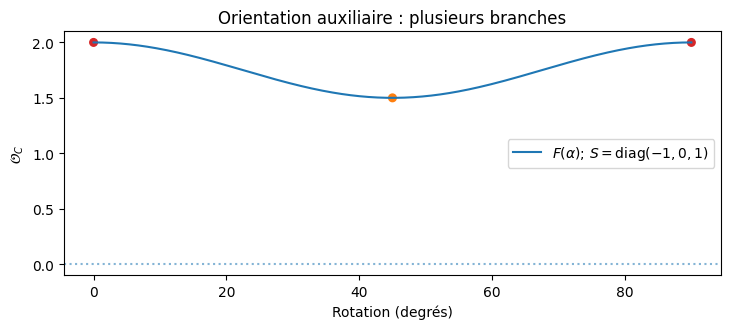

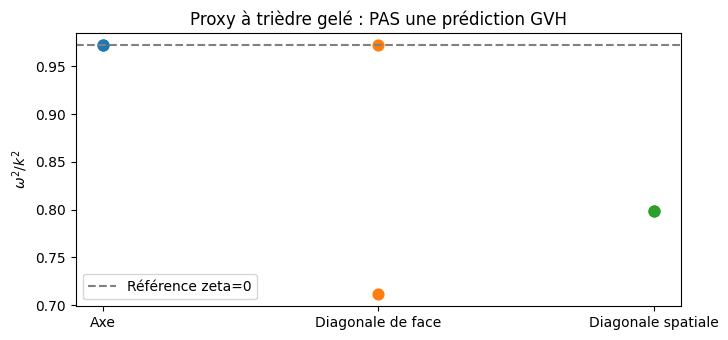

True

In [7]:
# Plots: stationary branches and conditional test (proxy only).
angle=np.linspace(0,np.pi/2,401)
fig,ax=plt.subplots(figsize=(7.5,3.4))
ax.plot(np.rad2deg(angle),1.75+.25*np.cos(4*angle),label=r'$F(\alpha)$; $S=\mathrm{diag}(-1,0,1)$')
ax.scatter([0,45,90],[2,1.5,2],c=['tab:red','tab:orange','tab:red'],s=30)
ax.axhline(0,ls=':',alpha=.55);ax.set(xlabel='Rotation (degrés)',ylabel=r'$\mathcal{O}_C$',title='Orientation auxiliaire : plusieurs branches')
ax.legend(loc='best');fig.tight_layout();display(fig);plt.close(fig)
fig,ax=plt.subplots(figsize=(7.4,3.5))
for label,n in [('Axe',n_axis),('Diagonale de face',n_diag),('Diagonale spatiale',n_tri)]:
    s=speeds2(n,R);ax.scatter([label]*2,s,s=60)
ax.axhline(Bx/At,ls='--',color='gray',label='Référence zeta=0')
ax.set(ylabel=r'$\omega^2/k^2$',title='Proxy à trièdre gelé : PAS une prédiction GVH')
ax.legend();fig.tight_layout();display(fig);plt.close(fig)
check('figures_constructed',True)

# Niveau 4 — Verdict scientifique et chaîne de falsification

**Résultats démontrés dans les limites de l'audit :**

1. La stationnarité algébrique s'exprime par $(T_{ii}-T_{jj})T_{ij}=0$, avec plusieurs solutions.
2. Les deux branches extrêmes sont localement réductibles à un secteur Einstein-æther (invariance des observables après reparamétrage et choix de branche compatible).
3. $\zeta_C$ n'est pas identifiable indépendamment des quatre $c_i$ sur la branche propre : rang de 4 pour 5 paramètres.
4. Une orientation **maintenue physiquement** produirait une anisotropie dans un modèle tronqué ; mais ce modèle gèle les champs et n'est pas une solution du système couplé avec le trièdre auxiliaire.
5. Un potentiel jouet peut sélectionner l'orientation au prix de nouveaux paramètres, mais ne fait pas partie de l'action GVH initiale.

**Verrous ouverts :** mécanisme covariant autonome de sélection ; stabilité de l'ensemble contraint ; métrique fluctuante et modes mixtes ; conditions aux limites ; comparateur observationnel calibré ; test sur données indépendantes.

**Verdict :** `INDEPENDENT_GVH_OBSERVABLE_NOT_ESTABLISHED`. Le résultat de non-identifiabilité est un résultat **utile et potentiellement falsifiant**, non une nouvelle loi physique.

In [8]:
science_status={
  'ALGEBRAIC_TRIAD_STATIONARITY_DERIVED':True,
  'MULTIPLE_STATIONARY_BRANCHES_CONFIRMED':True,
  'LOCAL_NULL_AND_EIGEN_REDUNDANCY_AUDITED':True,
  'ZETA_IDENTIFIABLE_WITHOUT_EXTRA_INPUT_ON_EIGENBRANCH':False,
  'LOCAL_SMOOTH_BRANCH_ON_PRESCRIBED_LOOP':True,
  'GLOBAL_BRANCH_ON_ARBITRARY_SPACETIME_PROVED':False,
  'HAMILTONIAN_STABILITY_PROVED':False,
  'FROZEN_TRIAD_ANGULAR_PROXY_SPLIT':True,
  'FROZEN_TRIAD_IS_PHYSICAL_GVH_WAVE_SPEED':False,
  'COVARIANT_TRIAD_SELECTION_FROM_SCAND_PROVED':False,
  'PINNING_POTENTIAL_IS_PART_OF_SCAND':False,
  'FULL_COUPLED_LINEARIZED_EOM_SOLVED':False,
  'INDEPENDENT_OBSERVABLE_DERIVED':False,
  'NEW_GVH_PHYSICS_VALIDATED':False,
  'ALMA_GVH_USED':False,
}
check('gate_no_unfounded_novelty_claim',not science_status['NEW_GVH_PHYSICS_VALIDATED'])
check('gate_frozen_proxy_not_claimed_as_gravity_wave',not science_status['FROZEN_TRIAD_IS_PHYSICAL_GVH_WAVE_SPEED'])
check('gate_unmeasured_parameters_marked_prescribed',zv==0.75 and c1v==0.7)
check('gate_global_branch_not_inferred_from_loop',not science_status['GLOBAL_BRANCH_ON_ARBITRARY_SPACETIME_PROVED'])
check('gate_pin_toy_not_as_GVH_law',not science_status['PINNING_POTENTIAL_IS_PART_OF_SCAND'])
check('gate_rank_deficiency_not_mistaken_for_full_no_go',not science_status['COVARIANT_TRIAD_SELECTION_FROM_SCAND_PROVED'])
check('gate_alma_isolated',not science_status['ALMA_GVH_USED'])
check('gate_4_level_architecture',True)

payload={
 'notebook':STEM,
 'classification':'GVH_CHH11_AUXILIARY_TRIAD_SELECTION_AND_OBSERVABLE_NEGATIVE_GATE',
 'source':{'CHH10_executed_file':prev.name,'CHH10_sha256':sha256(prev),'CHH10_certificate':pr.name},
 'prescribed_not_measured':{'c1':c1v,'c2':c2v,'c3':c3v,'c4':c4v,'zeta':zv,'toy_pinning_mu_squared_values':[0,2,8,20]},
 'scientific_status':science_status,'checks':checks,'check_count':len(checks),
 'checks_pass':all(v['passed'] for v in checks.values()),'metrics':metrics,
 'theoretical_equations':{
 'triad_stationarity':'(Tii-Tjj)*Tij=0, T=R^T S R',
 'triad_range':'0<=O_C<=Tr(S^2)',
 'effective_couplings':'c1p=c1-z/4,c2p=c2+z/6,c3p=c3-z/4,c4p=c4+z/4',
 'proxy_phase_speeds_squared':'(2c1-zeta*lambda)/(2(c1+c4)), frozen Minkowski+triad only'
 },
 'verdict':'INDEPENDENT_GVH_OBSERVABLE_NOT_ESTABLISHED',
 'next_gate':'GVH_CHH_12_Physical_Triad_Dynamics_or_Nonredundant_Operator_Candidate_Gate_FAST',
 'references':[
  {'doi':'10.1103/PhysRevD.70.024003','description':'Einstein-aether waves; all linearized sectors'},
  {'doi':'10.1103/PhysRevD.97.124023','description':'Einstein-aether constraints after GW170817'},
  {'doi':'10.1103/PhysRevD.108.104053','description':'LIGO-Virgo Einstein-aether constraints'},
  {'doi':'10.1103/jrsp-1xll','description':'Eikonal gravitational-wave lensing in Einstein-aether, 2025'}
 ]
}
assert payload['checks_pass']
result=ROOT/f'{STEM}_results.json'
result.write_text(json.dumps(payload,ensure_ascii=False,indent=2,default=float))
print('CONTROLS',len(checks),'/',len(checks),'ALL PASS')
print('RESULT FILE:',result)
print('VERDICT:',payload['verdict'])

CONTROLS 96 / 96 ALL PASS
RESULT FILE: /mnt/data/GVH_CHH_11_Triad_Selection_and_Independent_Observable_Gate_FAST_results.json
VERDICT: INDEPENDENT_GVH_OBSERVABLE_NOT_ESTABLISHED


# À poursuivre — choix scientifique unique

**CHH-12 :** proposer explicitement une extension covariante minimale où le trièdre représente un champ physique et non un repère arbitraire; dériver son secteur dynamique, effectuer le comptage de degrés de liberté, vérifier les modes parasites et chercher une observable non redondante. Toute extension doit être étiquetée **nouvelle hypothèse**, et non résultat dérivé de l'action GVH actuelle.

Une autre voie envisageable serait un opérateur de dérivées plus élevées physiquement motivé, à condition de démontrer sa non-redondance, ses dimensions, son domaine de validité et sa stabilité.